# Proyek Analisis Data: [Bike-Sharing-dataset]
- **Nama:** [Atikah Fahira]
- **Email:** [fahiraatikah0@gmail.com]
- **ID Dicoding:** [DS322B6X0280]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Proyek ini bertujuan untuk menganalisis pola penyewaan
sepeda pada layanan Capital Bikeshare di Washington D.C.
selama periode 2011–2012. Analisis difokuskan pada perbedaan rata-rata jumlah
penyewaan berdasarkan musim serta perbandingan
proporsi pengguna casual dan registered berdasarkan
jenis hari.



- **Pertanyaan 1:** Bagaimana perbedaan rata-rata penyewaan sepeda antara musim (spring, summer, fall, winter) selama periode 2011–2012?
- **Pertanyaan 2:** Bagaimana perbandingan persentase penyewaan pengguna casual dan registered terhadap total penyewaan pada hari kerja dan hari non-kerja (akhir pekan dan hari libur) selama periode 2011–2012 untuk mendukung penyusunan strategi pemasaran berdasarkan segmen pengguna?


## Import Semua Packages/Library yang Digunakan

In [38]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

## Data Wrangling

### Gathering Data

Dataset menyediakan dua jenis data, yaitu data
penyewaan harian (day.csv) dan data penyewaan
per jam (hour.csv). Dalam proyek ini, day.csv digunakan sebagai dataset utama karena kedua pertanyaan bisnis berfokus pada perbandingan berdasarkan musim dan jenis hari.

#### Load df day

In [39]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [40]:
project_path = "/content/drive/MyDrive/Dicoding/Submission_bike_sharing"

day_df = pd.read_csv(
    os.path.join(project_path, "data", "day.csv")
)

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [41]:
print("Jumlah baris dan kolom:", day_df.shape)

Jumlah baris dan kolom: (731, 16)


**Insight:** (Opsional)
- Dataset `day.csv` berhasil dimuat dengan 731 baris dan 16 kolom, mencakup data harian dari 1 Januari 2011 hingga 31 Desember 2012.
- Kolom `dteday` masih bertipe object (string) dan perlu diubah menjadi datetime untuk analisis berbasis waktu.
- Kolom `season` berisi kode 1-4 yang perlu diberi label (Spring, Summer, Fall, Winter) agar mudah dibaca pada visualisasi.

### Assessing Data

Tahap assessing data dilakukan untuk mengidentifikasi
permasalahan kualitas data yang dapat memengaruhi
hasil analisis. Pemeriksaan meliputi missing value, data duplikat, kesesuaian tipe data, konsistensi jumlah penyewaan, serta nilai yang tidak valid.

In [42]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [43]:
print("Missing Value:")
print(day_df.isnull().sum())

Missing Value:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [44]:
# Memeriksa duplikasi seluruh baris
print("Jumlah baris duplikat:", day_df.duplicated().sum())

# Memeriksa duplikasi tanggal
print("Jumlah tanggal duplikat:", day_df["dteday"].duplicated().sum())

Jumlah baris duplikat: 0
Jumlah tanggal duplikat: 0


Masalah 1 : Memeriksa nilai negatif

In [45]:
print("Jumlah hum bernilai 0:", (day_df["hum"] == 0).sum())

print("Jumlah nilai negatif casual:", (day_df["casual"] < 0).sum())

print("Jumlah nilai negatif registered:", (day_df["registered"] < 0).sum())

print("Jumlah nilai negatif cnt:", (day_df["cnt"] < 0).sum())

Jumlah hum bernilai 0: 1
Jumlah nilai negatif casual: 0
Jumlah nilai negatif registered: 0
Jumlah nilai negatif cnt: 0


Masalah 2 : Memeriksa kategori yang tidak valid

In [46]:
print("Season:", sorted(day_df["season"].unique()))
print("Year:", sorted(day_df["yr"].unique()))
print("Month:", sorted(day_df["mnth"].unique()))
print("Holiday:", sorted(day_df["holiday"].unique()))
print("Weekday:", sorted(day_df["weekday"].unique()))
print("Workingday:", sorted(day_df["workingday"].unique()))
print("Weather:", sorted(day_df["weathersit"].unique()))

Season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Year: [np.int64(0), np.int64(1)]
Month: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
Holiday: [np.int64(0), np.int64(1)]
Weekday: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Workingday: [np.int64(0), np.int64(1)]
Weather: [np.int64(1), np.int64(2), np.int64(3)]


Masalah 3 : Memeriksa kesesuaian jumlah penyewaan

In [47]:
day_df["total_check"] = (
    day_df["casual"] + day_df["registered"]
)

inaccurate_data = day_df[
    day_df["cnt"] != day_df["total_check"]
]

print("Jumlah data tidak sesuai:", len(inaccurate_data))

inaccurate_data.head()

Jumlah data tidak sesuai: 0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,total_check


Masalah 4 : Mengidentifikasi nilai kategori

In [48]:
# Memeriksa nilai kategori
categorical_columns = [
    "season",
    "yr",
    "mnth",
    "holiday",
    "weekday",
    "workingday",
    "weathersit"
]

for column in categorical_columns:
    print(f"\n{column}")
    print(day_df[column].value_counts().sort_index())


season
season
1    181
2    184
3    188
4    178
Name: count, dtype: int64

yr
yr
0    365
1    366
Name: count, dtype: int64

mnth
mnth
1     62
2     57
3     62
4     60
5     62
6     60
7     62
8     62
9     60
10    62
11    60
12    62
Name: count, dtype: int64

holiday
holiday
0    710
1     21
Name: count, dtype: int64

weekday
weekday
0    105
1    105
2    104
3    104
4    104
5    104
6    105
Name: count, dtype: int64

workingday
workingday
0    231
1    500
Name: count, dtype: int64

weathersit
weathersit
1    463
2    247
3     21
Name: count, dtype: int64


Masalah 5 : Mengidentifikasi outlier

In [49]:
# Mengidentifikasi outlier menggunakan metode IQR

outlier_columns = ["cnt", "casual", "registered"]

for column in outlier_columns:
    Q1 = day_df[column].quantile(0.25)
    Q3 = day_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = day_df[
        (day_df[column] < lower_bound) |
        (day_df[column] > upper_bound)
    ]

    print(f"\nKolom: {column}")
    print("Batas bawah:", lower_bound)
    print("Batas atas:", upper_bound)
    print("Jumlah outlier:", len(outliers))


Kolom: cnt
Batas bawah: -1054.0
Batas atas: 10162.0
Jumlah outlier: 0

Kolom: casual
Batas bawah: -855.25
Batas atas: 2266.75
Jumlah outlier: 44

Kolom: registered
Batas bawah: -922.25
Batas atas: 8195.75
Jumlah outlier: 0


**Steps to Take:**
- Mengubah tipe data `dteday` dari object menjadi datetime.
- Memberi label pada kolom `season` (1=Spring, 2=Summer, 3=Fall, 4=Winter) dan `workingday` (0=Weekend/Holiday, 1=Working Day) agar lebih informatif.
- Memperbaiki 1 nilai `hum` yang bernilai 0 (tidak valid) dengan interpolasi.

**Insight:** (Opsional)
- Tidak ditemukan missing value maupun data duplikat pada dataset.
- Konsistensi data terjaga: nilai `cnt` selalu sama dengan `casual` + `registered`, dan tidak ada nilai negatif pada kolom jumlah penyewaan.
- Ditemukan 1 nilai tidak valid pada kolom `hum` (kelembapan) yang bernilai 0, yang secara fisik tidak mungkin terjadi.
- Kolom `dteday` masih bertipe object sehingga belum bisa digunakan untuk analisis time-series.

### Cleaning Data

In [50]:
# Mengubah tipe data dteday menjadi datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

# Memeriksa tipe data setelah konversi
print(day_df["dteday"].dtype)

datetime64[ns]


In [51]:
# Memeriksa informasi dataset setelah cleaning
day_df.info()

# Memeriksa missing value
print("\nMissing Value:")
print(day_df.isnull().sum())

# Memeriksa duplikasi
print("\nJumlah duplikasi:", day_df.duplicated().sum())

# Memeriksa kesesuaian total penyewaan
print(
    "\nJumlah data dengan total penyewaan tidak sesuai:",
    (day_df["cnt"] !=
     day_df["casual"] + day_df["registered"]).sum()
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   instant      731 non-null    int64         
 1   dteday       731 non-null    datetime64[ns]
 2   season       731 non-null    int64         
 3   yr           731 non-null    int64         
 4   mnth         731 non-null    int64         
 5   holiday      731 non-null    int64         
 6   weekday      731 non-null    int64         
 7   workingday   731 non-null    int64         
 8   weathersit   731 non-null    int64         
 9   temp         731 non-null    float64       
 10  atemp        731 non-null    float64       
 11  hum          731 non-null    float64       
 12  windspeed    731 non-null    float64       
 13  casual       731 non-null    int64         
 14  registered   731 non-null    int64         
 15  cnt          731 non-null    int64         
 16  total_ch

In [52]:
# 1. Mengubah tipe data dteday menjadi datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

# 2. Memberi label pada kolom season
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
day_df['season_label'] = day_df['season'].map(season_map)

# 3. Memberi label pada kolom workingday
workingday_map = {0: 'Weekend/Holiday', 1: 'Working Day'}
day_df['day_type'] = day_df['workingday'].map(workingday_map)

# 4. Memperbaiki nilai hum = 0 dengan interpolasi
day_df['hum'] = day_df['hum'].replace(0, np.nan)
day_df['hum'] = day_df['hum'].interpolate(method='linear')

# Verifikasi hasil
print("Tipe data dteday:", day_df['dteday'].dtype)
print("Nilai hum = 0 tersisa:", (day_df['hum'] == 0).sum())
print(day_df[['dteday', 'season_label', 'day_type', 'hum']].head())

Tipe data dteday: datetime64[ns]
Nilai hum = 0 tersisa: 0
      dteday season_label         day_type       hum
0 2011-01-01       Spring  Weekend/Holiday  0.805833
1 2011-01-02       Spring  Weekend/Holiday  0.696087
2 2011-01-03       Spring      Working Day  0.437273
3 2011-01-04       Spring      Working Day  0.590435
4 2011-01-05       Spring      Working Day  0.436957


**Insight:** (Opsional)
- Dataset memiliki 731 observasi dan 16 variabel tanpa missing value, sehingga tidak diperlukan penghapusan maupun imputasi data akibat nilai yang hilang.

- Tidak ditemukan nilai negatif pada variabel casual, registered, dan cnt, tetapi terdapat satu observasi dengan nilai hum sebesar 0 yang memerlukan pemeriksaan lebih lanjut.

- Seluruh variabel kategorikal memiliki rentang nilai yang sesuai dengan ketentuan dataset, sehingga tidak ditemukan kategori yang tidak valid.

- Tidak ditemukan ketidaksesuaian antara total penyewaan (cnt) dengan penjumlahan pengguna casual dan registered. Hal ini menunjukkan konsistensi pencatatan jumlah penyewaan.

- Distribusi data mencakup dua tahun pengamatan, yaitu 2011 sebanyak 365 observasi dan 2012 sebanyak 366 observasi. Jumlah observasi pada setiap musim relatif seimbang, sedangkan hari kerja memiliki 500 observasi dan hari non-kerja sebanyak 231 observasi.

- Identifikasi outlier menggunakan metode IQR menunjukkan 44 observasi pada variabel casual, sementara variabel cnt dan registered tidak memiliki outlier. Nilai outlier dipertahankan karena berpotensi merepresentasikan peningkatan permintaan penyewaan yang sebenarnya.

- Kolom dteday memiliki tipe data awal object, sehingga perlu dikonversi menjadi datetime untuk mendukung analisis berdasarkan tanggal dan periode waktu.

## Exploratory Data Analysis (EDA)

### Explore: Perbedaan rata-rata penyewaan berdasarkan musim (Pertanyaan 1)

Analisis ini bertujuan untuk mengetahui perbedaan
tingkat penyewaan sepeda pada setiap musim selama
periode 2011–2012. Pengelompokan dilakukan berdasarkan kategori musim,
kemudian dihitung jumlah hari pengamatan, total
penyewaan, rata-rata penyewaan harian, dan median
penyewaan harian.

In [53]:
# Mengelompokkan data berdasarkan jenis hari
user_analysis = (
    day_df.groupby("day_type")
    .agg(
        total_casual=("casual", "sum"),
        total_registered=("registered", "sum"),
        total_penyewaan=("cnt", "sum")
    )
)

user_analysis

,total_casual,total_registered,total_penyewaan
day_type,,,
Weekend/Holiday,316732,683537,1000269
Working Day,303285,1989125,2292410


In [54]:
season_order = ["Spring", "Summer", "Fall", "Winter"]

season_analysis = (
    day_df.groupby("season_label")
    .agg(
        jumlah_hari=("cnt", "count"),
        total_penyewaan=("cnt", "sum"),
        rata_rata_penyewaan=("cnt", "mean"),
        median_penyewaan=("cnt", "median")
    )
    .reindex(season_order)
    .round(2)
)

season_analysis

,jumlah_hari,total_penyewaan,rata_rata_penyewaan,median_penyewaan
season_label,,,,
Spring,181,471348,2604.13,2209.0
Summer,184,918589,4992.33,4941.5
Fall,188,1061129,5644.30,5353.5
Winter,178,841613,4728.16,4634.5


In [55]:
highest_season = season_analysis["rata_rata_penyewaan"].idxmax()
lowest_season = season_analysis["rata_rata_penyewaan"].idxmin()

highest_value = season_analysis.loc[
    highest_season, "rata_rata_penyewaan"
]

lowest_value = season_analysis.loc[
    lowest_season, "rata_rata_penyewaan"
]

print("Musim dengan rata-rata tertinggi:", highest_season)
print("Rata-rata penyewaan:", round(highest_value, 2))

print("\nMusim dengan rata-rata terendah:", lowest_season)
print("Rata-rata penyewaan:", round(lowest_value, 2))

Musim dengan rata-rata tertinggi: Fall
Rata-rata penyewaan: 5644.3

Musim dengan rata-rata terendah: Spring
Rata-rata penyewaan: 2604.13


In [56]:
season_year = (
    day_df.groupby(["season_label", "yr"])["cnt"]
    .mean()
    .unstack()
    .reindex(season_order)
    .round(2)
)

season_year

yr,0,1
season_label,,
Spring,1666.67,3531.30
Summer,3775.17,6209.49
Fall,4464.36,6824.24
Winter,3664.46,5791.87


### Explore: Perbandingan pengguna Casual dan Registered (Pertanyaan 2)

Analisis ini bertujuan untuk membandingkan kontribusi pengguna Casual dan Registered terhadap total penyewaan sepeda berdasarkan jenis hari. Pengelompokan dilakukan menjadi hari kerja dan hari non-kerja (akhir pekan dan hari libur). Selanjutnya, dihitung total penyewaan masing-masing segmen dan persentase kontribusinya terhadap keseluruhan penyewaan pada setiap kelompok hari.

In [57]:
user_analysis["persentase_casual"] = (
    user_analysis["total_casual"] /
    user_analysis["total_penyewaan"] * 100
)

user_analysis["persentase_registered"] = (
    user_analysis["total_registered"] /
    user_analysis["total_penyewaan"] * 100
)

user_analysis.round(2)

,total_casual,total_registered,total_penyewaan,persentase_casual,persentase_registered
day_type,,,,,
Weekend/Holiday,316732,683537,1000269,31.66,68.34
Working Day,303285,1989125,2292410,13.23,86.77


In [58]:
daily_user_analysis = (
    day_df.groupby("day_type")
    .agg(
        rata_rata_casual=("casual", "mean"),
        rata_rata_registered=("registered", "mean"),
        rata_rata_total=("cnt", "mean")
    )
    .round(2)
)

daily_user_analysis

,rata_rata_casual,rata_rata_registered,rata_rata_total
day_type,,,
Weekend/Holiday,1371.13,2959.03,4330.17
Working Day,606.57,3978.25,4584.82


**Insight:** (Opsional)
- Dataset mencakup periode pengamatan tahun 2011–2012 sehingga dapat digunakan untuk mengidentifikasi pola penyewaan sepeda berdasarkan musim dan jenis hari.
- Variabel casual dan registered menunjukkan dua kelompok pengguna dengan karakteristik penyewaan yang berbeda, sehingga perlu dianalisis secara terpisah.
- Variabel cnt digunakan untuk menggambarkan total penyewaan sepeda dan menjadi indikator utama dalam mengidentifikasi tingkat permintaan.
- Pengelompokan data berdasarkan musim dan jenis hari membantu mengidentifikasi pola serta perbedaan perilaku penyewaan pengguna.
- Perbandingan jumlah dan rata-rata penyewaan diperlukan untuk mengetahui periode dengan tingkat permintaan tertinggi dan terendah.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perbedaan rata-rata penyewaan sepeda antara musim Spring, Summer, Fall, dan Winter selama periode 2011–2012?

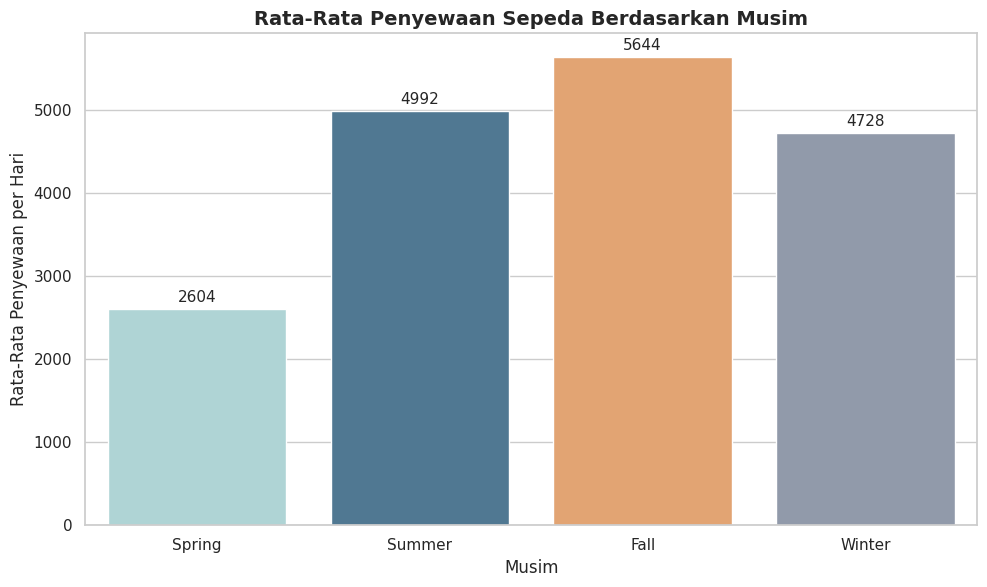

In [59]:
plt.figure(figsize=(10, 6))

colors = ["#A8DADC", "#457B9D", "#F4A261", "#8D99AE"]

ax = sns.barplot(
    data=season_analysis.reset_index(),
    x="season_label",
    y="rata_rata_penyewaan",
    hue="season_label",
    order=season_order,
    palette=colors,
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title(
    "Rata-Rata Penyewaan Sepeda Berdasarkan Musim",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Musim")
plt.ylabel("Rata-Rata Penyewaan per Hari")

plt.tight_layout()
plt.show()

Berdasarkan hasil visualisasi, musim Fall memiliki rata-rata penyewaan sepeda tertinggi sebesar 5.644 penyewaan per hari, sedangkan musim Spring memiliki rata-rata terendah sebesar 2.604 penyewaan per hari. Temuan ini menunjukkan bahwa tingkat permintaan penyewaan sepeda berbeda pada setiap musim. Oleh karena itu, pola permintaan musiman dapat menjadi pertimbangan dalam perencanaan ketersediaan armada dan pengelolaan operasional layanan.

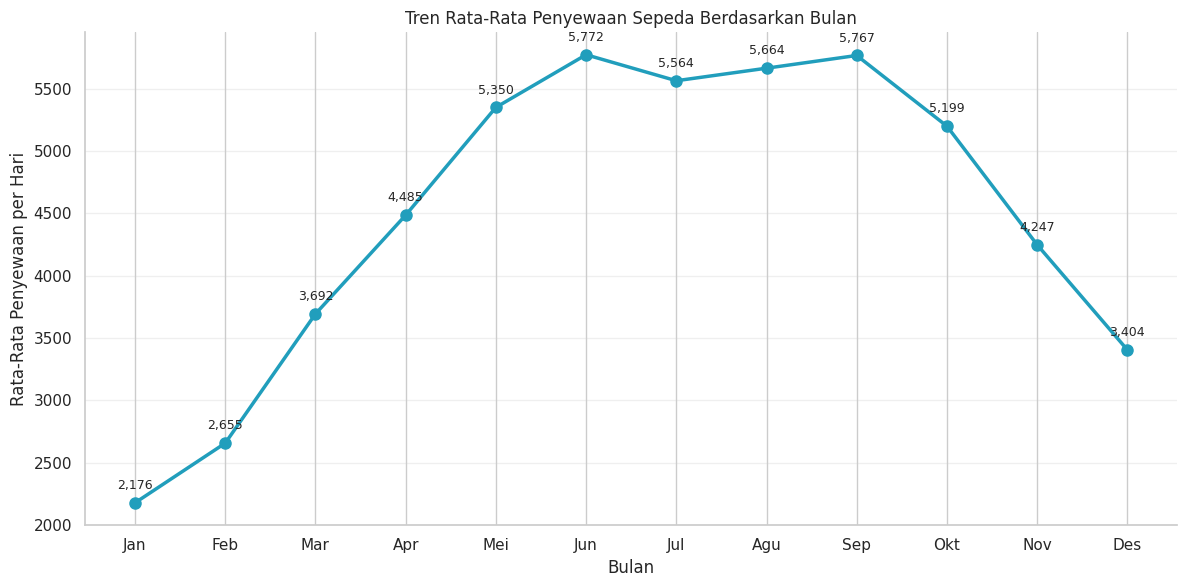

In [66]:
# Menghitung rata-rata penyewaan setiap bulan
monthly_analysis = (
    day_df.groupby("mnth")["cnt"]
    .mean()
    .reindex(range(1, 13))
)

nama_bulan = [
    "Jan", "Feb", "Mar", "Apr", "Mei", "Jun",
    "Jul", "Agu", "Sep", "Okt", "Nov", "Des"
]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    monthly_analysis.index,
    monthly_analysis.values,
    marker="o",
    markersize=8,
    linewidth=2.5,
    color="#219EBC"
)

# Memberikan label pada setiap titik
for bulan, nilai in monthly_analysis.items():
    ax.annotate(
        f"{nilai:,.0f}",
        (bulan, nilai),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontsize=9
    )

ax.set_title("Tren Rata-Rata Penyewaan Sepeda Berdasarkan Bulan")
ax.set_xlabel("Bulan")
ax.set_ylabel("Rata-Rata Penyewaan per Hari")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(nama_bulan)
ax.grid(axis="y", alpha=0.3)

sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana perbandingan persentase penyewaan pengguna casual dan registered terhadap total penyewaan pada hari kerja dan hari non-kerja (akhir pekan dan hari libur) selama periode 2011–2012 untuk mendukung penyusunan strategi pemasaran berdasarkan segmen pengguna?

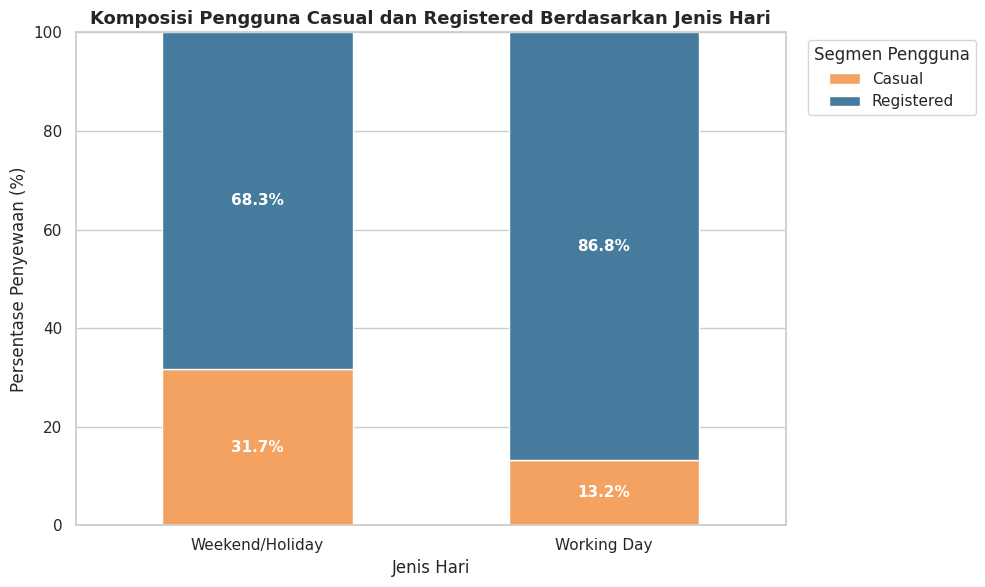

In [60]:
plot_user = user_analysis[
    ["persentase_casual", "persentase_registered"]
].copy()

ax = plot_user.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#F4A261", "#457B9D"],
    width=0.55
)

for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%"
        if bar.get_height() > 0 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        color="white",
        fontweight="bold"
    )

plt.title(
    "Komposisi Pengguna Casual dan Registered Berdasarkan Jenis Hari",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Jenis Hari")
plt.ylabel("Persentase Penyewaan (%)")
plt.ylim(0, 100)

plt.legend(
    ["Casual", "Registered"],
    title="Segmen Pengguna",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Berdasarkan visualisasi, pengguna Registered
mendominasi penyewaan pada hari kerja dengan
kontribusi sekitar 86,77%.

Sebaliknya, kontribusi pengguna Casual meningkat
menjadi sekitar 31,66% pada hari non-kerja.

Temuan tersebut menunjukkan adanya perbedaan
komposisi segmen pengguna berdasarkan jenis hari.

Oleh karena itu, strategi pemasaran dapat
disesuaikan dengan karakteristik pengguna pada
masing-masing kelompok hari.

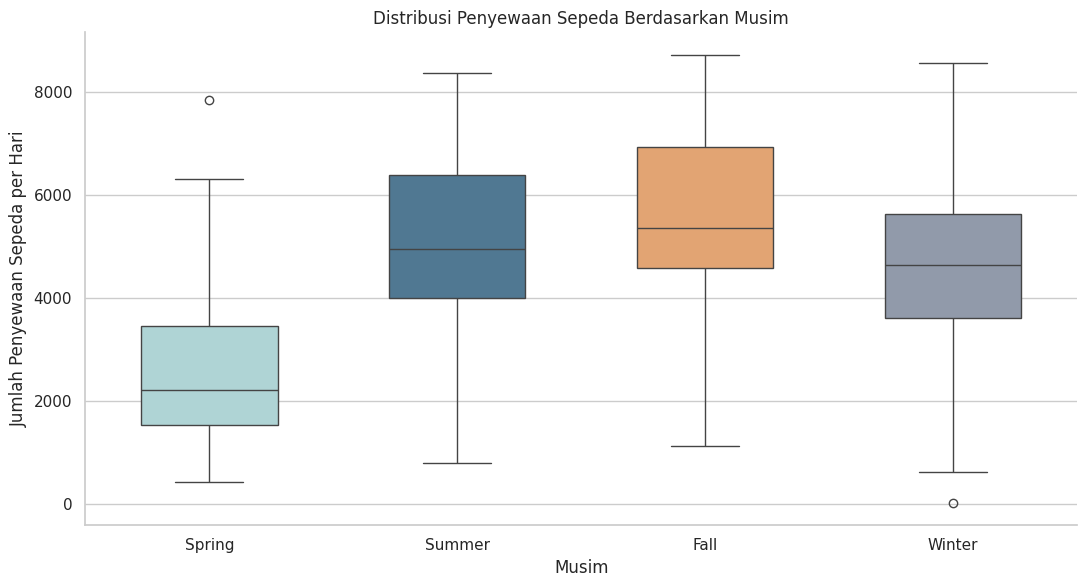

In [69]:
# Palet warna untuk setiap musim
warna_musim = {
    "Spring": "#A8DADC",
    "Summer": "#457B9D",
    "Fall": "#F4A261",
    "Winter": "#8D99AE"
}

fig, ax = plt.subplots(figsize=(11, 6))

sns.boxplot(
    data=day_df,
    x="season_label",
    y="cnt",
    order=season_order,
    hue="season_label",
    palette=warna_musim,
    legend=False,
    width=0.55,
    ax=ax
)

ax.set_title("Distribusi Penyewaan Sepeda Berdasarkan Musim")
ax.set_xlabel("Musim")
ax.set_ylabel("Jumlah Penyewaan Sepeda per Hari")

sns.despine()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Visualisasi rata-rata penyewaan berdasarkan musim digunakan untuk mengidentifikasi perbedaan tingkat permintaan sepeda pada setiap musim.
- Perbandingan rata-rata penyewaan dapat menunjukkan musim dengan aktivitas penyewaan tertinggi dan terendah.
- Visualisasi proporsi pengguna casual dan registered berdasarkan jenis hari digunakan untuk memahami perbedaan kontribusi kedua kelompok pengguna.
- Perbandingan persentase pengguna dapat menunjukkan kelompok yang lebih dominan pada hari kerja maupun hari non-kerja.
- Hasil visualisasi memberikan gambaran mengenai pola permintaan dan karakteristik pengguna yang dapat menjadi dasar dalam penyusunan strategi pemasaran.

## Analisis Lanjutan (Opsional)

Teknik binning digunakan untuk mengelompokkan
jumlah penyewaan harian menjadi tiga kategori,
yaitu Rendah, Sedang, dan Tinggi.

Pengelompokan dilakukan berdasarkan distribusi
jumlah penyewaan menggunakan kuantil sehingga
setiap kategori memiliki batas berdasarkan
karakteristik data.

In [61]:
day_df["kategori_permintaan"] = pd.qcut(
    day_df["cnt"],
    q=3,
    labels=["Rendah", "Sedang", "Tinggi"]
)

day_df["kategori_permintaan"].value_counts()

,count
kategori_permintaan,
Rendah,244
Sedang,244
Tinggi,243


In [62]:
demand_season = pd.crosstab(
    day_df["season_label"],
    day_df["kategori_permintaan"],
    normalize="index"
) * 100

demand_season.round(2)

kategori_permintaan,Rendah,Sedang,Tinggi
season_label,,,
Fall,6.91,42.02,51.06
Spring,77.35,18.23,4.42
Summer,20.11,38.59,41.30
Winter,30.34,34.27,35.39


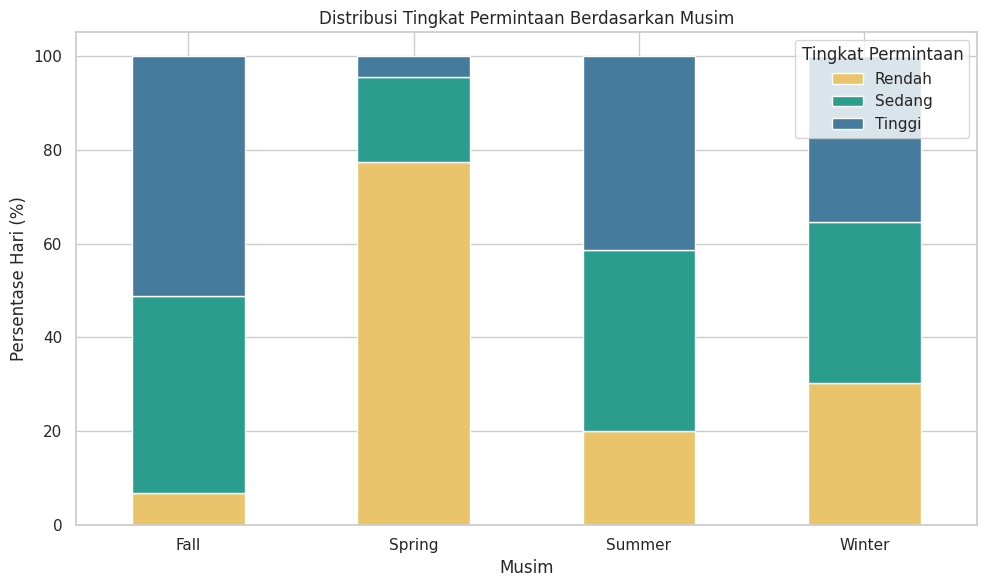

In [63]:
demand_season.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#E9C46A", "#2A9D8F", "#457B9D"]
)

plt.title("Distribusi Tingkat Permintaan Berdasarkan Musim")
plt.xlabel("Musim")
plt.ylabel("Persentase Hari (%)")
plt.legend(title="Tingkat Permintaan")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Pengelompokan tingkat permintaan penyewaan ke dalam kategori rendah, sedang, dan tinggi dapat membantu mengidentifikasi periode dengan intensitas penggunaan sepeda yang berbeda.
- Kategorisasi permintaan berdasarkan jumlah penyewaan memungkinkan perbandingan karakteristik setiap musim terhadap tingkat permintaan.
- Analisis segmentasi pengguna casual dan registered membantu mengidentifikasi kelompok pengguna yang memiliki kontribusi berbeda terhadap total penyewaan.
- Perbedaan proporsi pengguna berdasarkan jenis hari dapat dimanfaatkan untuk menentukan pendekatan pemasaran yang sesuai dengan karakteristik masing-masing kelompok.
- Hasil analisis lanjutan dapat digunakan untuk menyusun rekomendasi terkait promosi, pengelolaan ketersediaan sepeda, dan penyesuaian strategi pemasaran berdasarkan periode permintaan.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan analisis rata-rata penyewaan
   berdasarkan musim, terdapat perbedaan tingkat
   permintaan yang jelas pada setiap musim. Fall menunjukkan
   rata-rata penyewaan tertinggi (5.644 per hari), diikuti Summer
   (4.992 per hari) dan Winter (4.728 per hari), sedangkan Spring
   menunjukkan rata-rata penyewaan terendah (2.604 per hari).
   Hal ini menunjukkan bahwa musim merupakan
   salah satu karakteristik yang berkaitan dengan
   variasi permintaan penyewaan sepeda.
- **Conclusion pertanyaan 2:** Berdasarkan segmentasi pengguna, Registered
   mendominasi penyewaan pada hari kerja dengan
   kontribusi 86,77%, sedangkan Casual memiliki
   kontribusi lebih besar pada hari non-kerja,
   yaitu 31,66%. Hal ini menunjukkan adanya
   perbedaan komposisi pengguna berdasarkan
   jenis hari.


**Rekomendasi Action Item:**
- Pengelola layanan dapat menyesuaikan
   ketersediaan armada berdasarkan pola permintaan
   musiman, dengan memperhatikan peningkatan
   permintaan pada musim Fall dan Summer serta penurunan
   permintaan pada musim Spring (periode yang dapat
   dimanfaatkan untuk perawatan armada atau program promosi).

- Strategi pemasaran untuk pengguna Registered
   dapat difokuskan pada program loyalitas,
   penawaran perpanjangan keanggotaan, dan
   paket langganan yang mendukung kebutuhan
   perjalanan rutin pada hari kerja.

- Strategi pemasaran untuk pengguna Casual
   dapat diarahkan pada promosi akhir pekan,
   paket penyewaan harian, dan kampanye rekreasi
   untuk meningkatkan keterlibatan pengguna
   non-berlangganan.

In [64]:
dashboard_path = os.path.join(project_path, "dashboard")

os.makedirs(dashboard_path, exist_ok=True)

day_df.to_csv(
    os.path.join(dashboard_path, "main_data.csv"),
    index=False
)

print("Dataset berhasil disimpan!")

Dataset berhasil disimpan!


In [65]:
pd.read_csv(
    os.path.join(dashboard_path, "main_data.csv")
).head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,total_check,season_label,day_type,kategori_permintaan
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,985,Spring,Weekend/Holiday,Rendah
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,801,Spring,Weekend/Holiday,Rendah
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,1349,Spring,Working Day,Rendah
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,1562,Spring,Working Day,Rendah
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,1600,Spring,Working Day,Rendah
